Simple Linear Regression

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

خواندن دیتاست


In [2]:
dataset = pd.read_csv("DB\Hours and Scores.csv")
dataset.head()

<>:1: SyntaxWarning: invalid escape sequence '\H'
<>:1: SyntaxWarning: invalid escape sequence '\H'
C:\Users\Asus\AppData\Local\Temp\ipykernel_39116\2778057730.py:1: SyntaxWarning: invalid escape sequence '\H'
  dataset = pd.read_csv("DB\Hours and Scores.csv")


,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30


جداسازی داده ها


In [3]:
x = dataset.iloc[:, 0]
x.shape

(25,)

In [4]:
x = dataset.iloc[:, :-1]
x.shape

(25, 1)

In [5]:
y = dataset.iloc[:, 1]
y.shape

(25,)

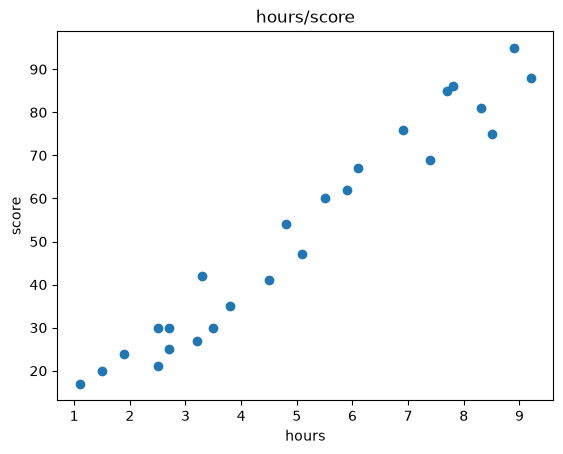

In [6]:
plt.scatter(x, y)
plt.title("hours/score")
plt.xlabel("hours")
plt.ylabel("score")
plt.show()

In [7]:
x_test, x_train, y_test, y_train = train_test_split(x, y, test_size=0.2, random_state=42)

تعریف مدل

In [ ]:
regressor_model = LinearRegression()
regressor_model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[10.18]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.8684
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [11]:
# y = mx + b
m = regressor_model.coef_[0]
b = regressor_model.intercept_

print(f"y = {m:.2f}x + {b:.2f}")

y = 10.18x + 0.87


حالا پیشبینی

In [12]:
y_pred = regressor_model.predict(x_test)

df = pd.DataFrame({
    "Actual": y_test,
    "Predict": y_pred
})

df

,Actual,Predict
9,25,28.350261
13,42,34.457342
1,47,52.778584
22,35,39.546576
5,20,16.136100
2,27,33.439495
12,41,46.671503
15,95,91.456761
3,75,87.385374
4,30,36.493035


ارزیابی مدل  

* MAE  
* MSE  
* RMSE

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"MAE: {mae:.2f}, MSE: {mse:.2f}, RMSE: {rmse:.2f}")

MAE: 5.33, MSE: 33.25, RMSE: 5.77


نرمالایز کردن دیتاست

In [14]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

regressor_model = LinearRegression()
regressor_model.fit(x_train, y_train)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"MAE: {mae:.2f}, MSE: {mse:.2f}, RMSE: {rmse:.2f}")

MAE: 5.33, MSE: 33.25, RMSE: 5.77
